# Extreme Gradient Boosting (XGBoost): The Tabular King

Gradient Boosting is the current state-of-the-art for tabular data, outperforming even Deep Learning on most structured datasets. Instead of building independent trees like Random Forest, XGBoost builds trees sequentially, where each new tree tries to fix the residual errors of the previous ones.

In this notebook, we'll build an advanced `XGBRegressor` on the California Housing dataset, complete with evaluation sets and early stopping.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import xgboost as xgb

# Clean graphing style
plt.style.use('bmh')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Load the Data
We're predicting the median house value in California blocks based on metrics like median income, average rooms, and geographical coordinates.

In [ ]:
data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target  # Median house value in $100,000s

# We'll split into Train and Test. 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
display(X_train.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80


## 2. Advanced Training with Early Stopping
A massive problem with boosting is that if you add too many trees, it will overfit perfectly to the training data. To prevent this, we use an **evaluation set**. The algorithm will monitor the error on the unseen test set, and if the error stops improving, it will halt training automatically! Note: XGBoost natively handles this via the `early_stopping_rounds` parameter in `fit`.

In [ ]:
model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=1000,      # Huge number of trees, but early stopping will cut it short!
    learning_rate=0.05,     # Slow learning rate makes the model robust
    max_depth=6,            # Shallow trees prevent overfitting
    subsample=0.8,          # Randomly sample 80% of data per tree
    colsample_bytree=0.8,   # Randomly sample 80% of features per tree
    early_stopping_rounds=20,
    random_state=42
)

# Pass the test set as the evaluation set to monitor overfitting
eval_set = [(X_train, y_train), (X_test, y_test)]

model.fit(
    X_train, y_train,
    eval_set=eval_set,
    verbose=False  # Keep output clean
)

print(f"Training stopped early at tree {model.best_iteration} out of 1000 to prevent overfitting!")

Training stopped early at tree 998 out of 1000 to prevent overfitting!


## 3. Visualize the Learning Curve
Let's extract the evaluation metrics during training to prove that we successfully halted training before the test error started rising.

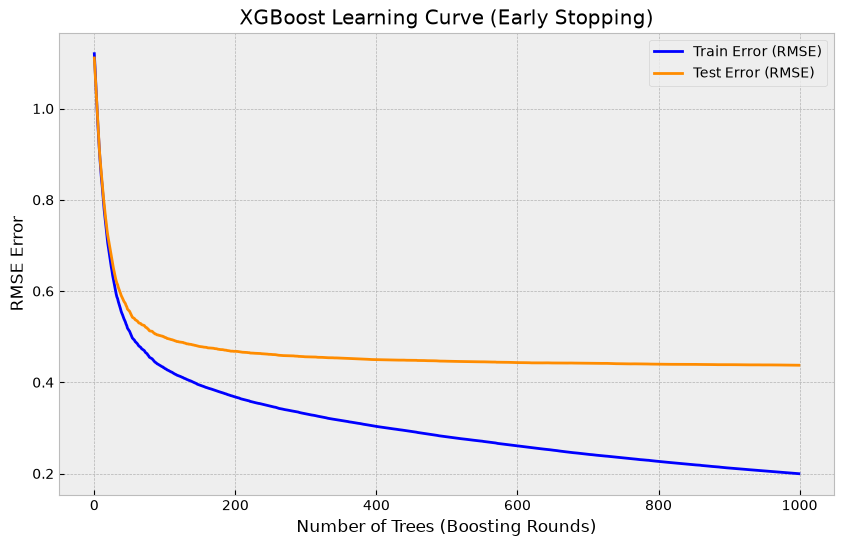

In [ ]:
results = model.evals_result()
epochs = len(results['validation_0']['rmse'])
x_axis = range(0, epochs)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_axis, results['validation_0']['rmse'], label='Train Error (RMSE)', lw=2, color='blue')
ax.plot(x_axis, results['validation_1']['rmse'], label='Test Error (RMSE)', lw=2, color='darkorange')
ax.legend()
plt.ylabel('RMSE Error')
plt.xlabel('Number of Trees (Boosting Rounds)')
plt.title('XGBoost Learning Curve (Early Stopping)')
plt.show()

## 4. Final Evaluation & Feature Importance
Just like Random Forest, we can ask XGBoost what features actually matter. In California, is it the number of rooms, or just the location?

Final Model RMSE: 0.4374


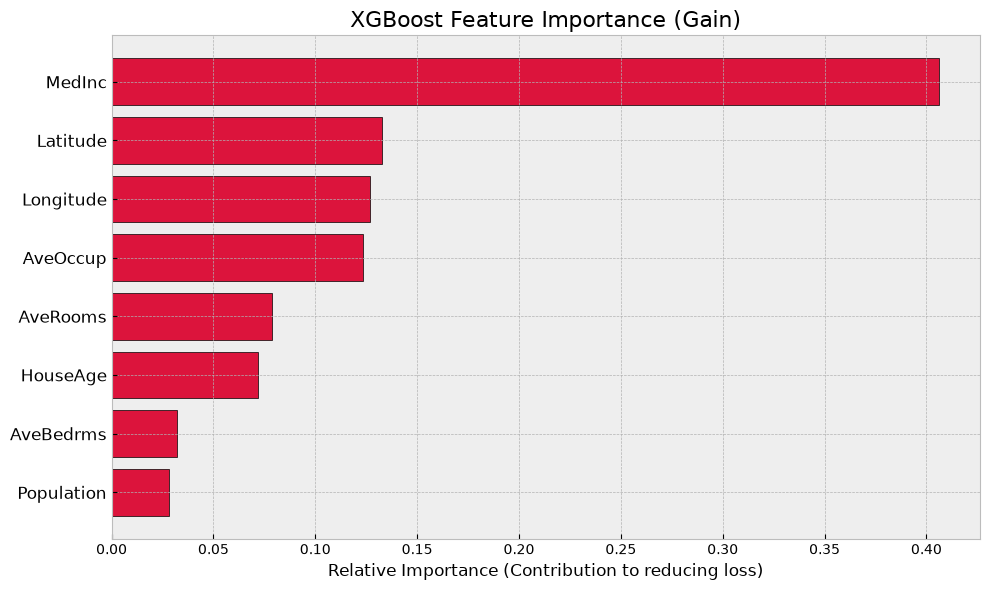

In [ ]:
preds = model.predict(X_test)
final_rmse = np.sqrt(mean_squared_error(y_test, preds))
print(f"Final Model RMSE: {final_rmse:.4f}")

# Feature Importance Plot
importances = model.feature_importances_
indices = np.argsort(importances)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(indices)), importances[indices], color='crimson', edgecolor='black')
ax.set_yticks(range(len(indices)))
ax.set_yticklabels(np.array(data.feature_names)[indices], fontsize=12)
ax.set_title('XGBoost Feature Importance (Gain)', fontsize=16)
ax.set_xlabel('Relative Importance (Contribution to reducing loss)', fontsize=12)
plt.tight_layout()
plt.show()